In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

if os.path.exists("mnist_train.csv.zip") and os.path.exists("mnist_test.csv.zip"):
    print("Loading dataset from local ZIP files...")
    train_df = pd.read_csv("mnist_train.csv.zip")
    test_df = pd.read_csv("mnist_test.csv.zip")

    print("Training Dataset Shape:", train_df.shape)
    print("Testing Dataset Shape:", test_df.shape)

    X = train_df.iloc[:, 1:].values
    y = train_df.iloc[:, 0].values

    X_test = test_df.iloc[:, 1:].values
    y_test = test_df.iloc[:, 0].values

    X = X / 255.0
    X_test = X_test / 255.0

    X = X.reshape(-1, 28, 28, 1)
    X_test = X_test.reshape(-1, 28, 28, 1)
else:
    print("Local training file not found. Falling back to downloading MNIST via Keras...")
    mnist = tf.keras.datasets.mnist
    (X, y), (X_test, y_test) = mnist.load_data()

    X = X / 255.0
    X_test = X_test / 255.0

    X = X.reshape(-1, 28, 28, 1)
    X_test = X_test.reshape(-1, 28, 28, 1)

print("\nPreprocessing completed!")
print("Training Images Shape:", X.shape)
print("Testing Images Shape:", X_test.shape)
print("Training Labels Shape:", y.shape)
print("Testing Labels Shape:", y_test.shape)

Local training file not found. Falling back to downloading MNIST via Keras...

Preprocessing completed!
Training Images Shape: (60000, 28, 28, 1)
Testing Images Shape: (10000, 28, 28, 1)
Training Labels Shape: (60000,)
Testing Labels Shape: (10000,)


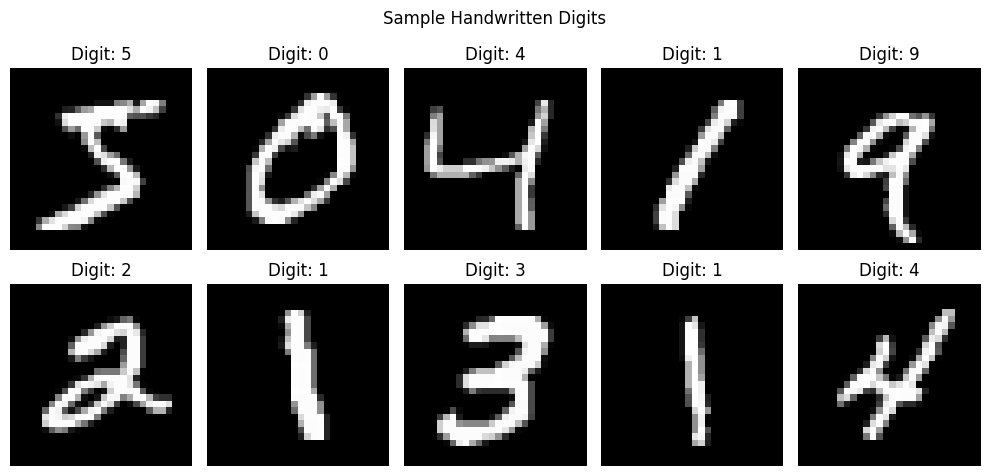

In [ ]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X[i].squeeze(), cmap='gray')
    plt.title("Digit: " + str(y[i]))
    plt.axis('off')

plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

In [ ]:
with tf.device('/CPU:0'):

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(28, 28, 1)),

        tf.keras.layers.Conv2D(32, (3,3), activation='relu'),

        tf.keras.layers.MaxPooling2D((2,2)),

        tf.keras.layers.Conv2D(64, (3,3), activation='relu'),

        tf.keras.layers.MaxPooling2D((2,2)),

        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(128, activation='relu'),

        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(10, activation='softmax')
    ])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
with tf.device('/CPU:0'):

    history = model.fit(
        X,
        y,
        epochs=5,
        batch_size=128,
        validation_split=0.1,
        verbose=1
    )

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 107ms/step - accuracy: 0.9194 - loss: 0.2635 - val_accuracy: 0.9837 - val_loss: 0.0591
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9775 - loss: 0.0744 - val_accuracy: 0.9850 - val_loss: 0.0512
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9831 - loss: 0.0542 - val_accuracy: 0.9905 - val_loss: 0.0351
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 104ms/step - accuracy: 0.9866 - loss: 0.0425 - val_accuracy: 0.9888 - val_loss: 0.0407
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 106ms/step - accuracy: 0.9884 - loss: 0.0373 - val_accuracy: 0.9902 - val_loss: 0.0355


In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9897 - loss: 0.0285
Test Accuracy: 98.97000193595886 %
Test Loss: 0.02854769676923752


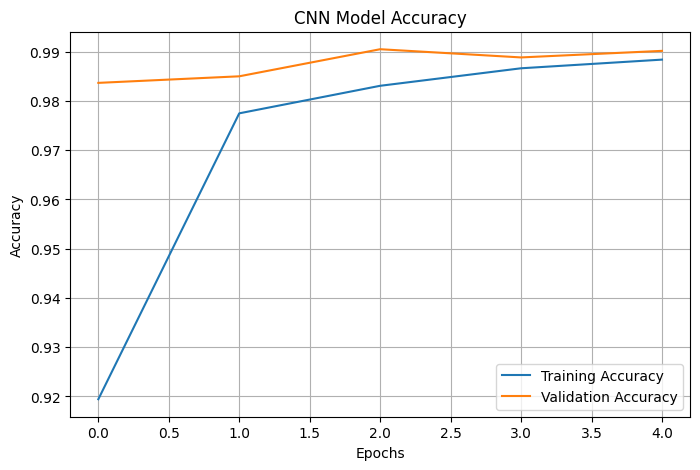

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

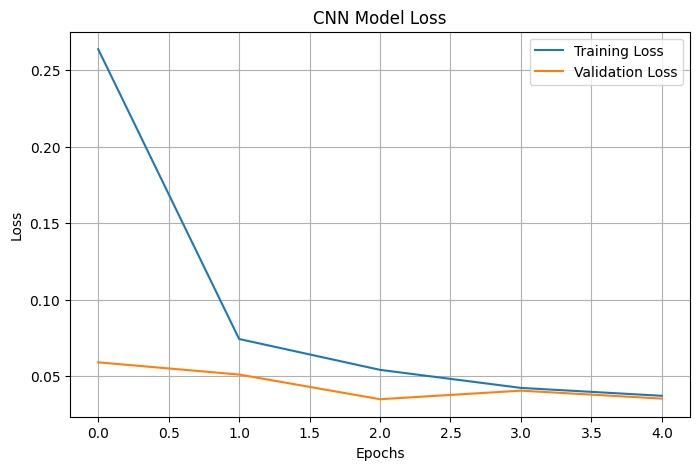

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


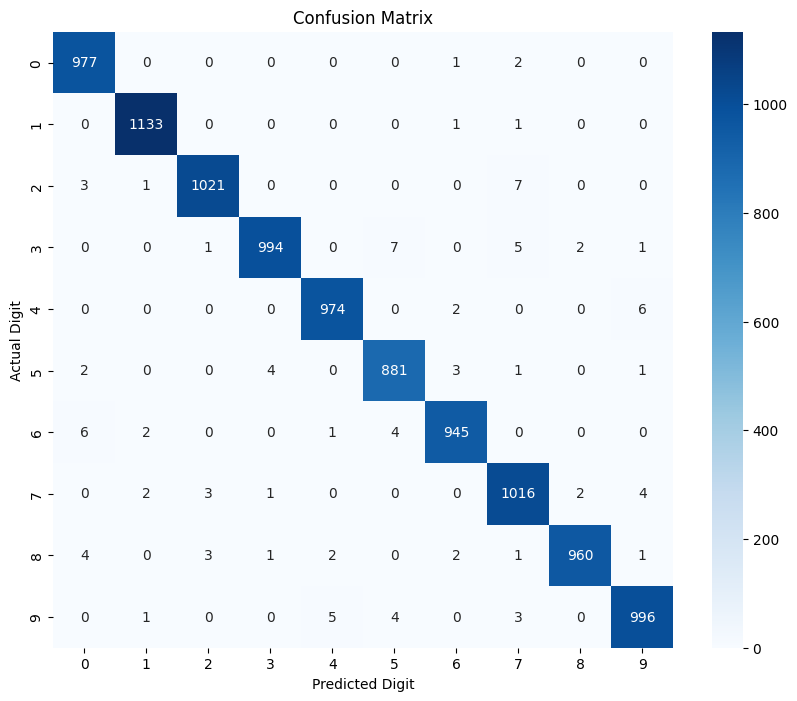

In [ ]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

In [ ]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred_classes
))

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.98      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.98      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



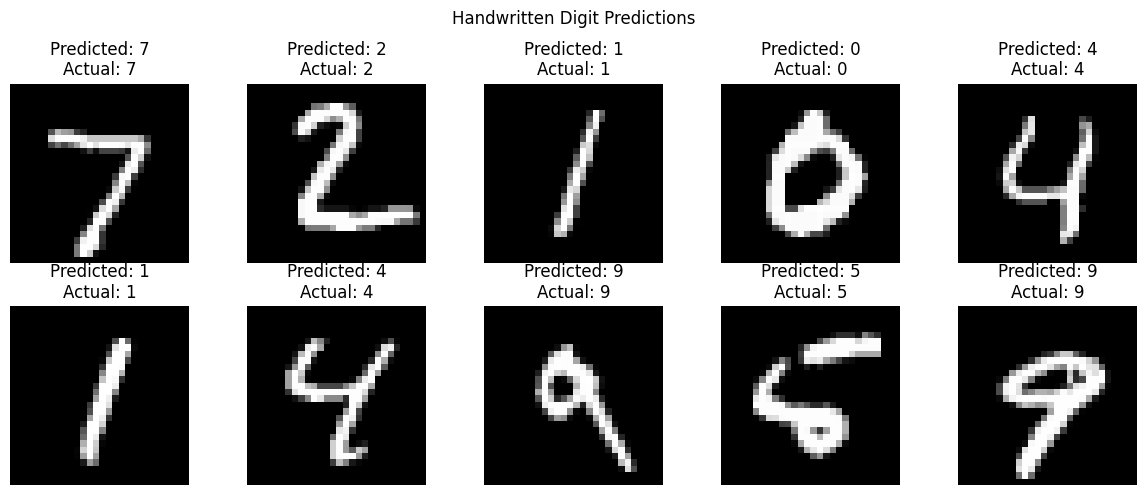

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(X_test[i].squeeze(), cmap='gray')

    prediction = y_pred_classes[i]

    plt.title(
        "Predicted: " + str(prediction) +
        "\nActual: " + str(y_test[i])
    )

    plt.axis('off')

plt.suptitle("Handwritten Digit Predictions")
plt.tight_layout()
plt.show()

In [ ]:
model.save("handwritten_digit_model.keras")

print("Model saved successfully!")

from google.colab import files
files.download("handwritten_digit_model.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

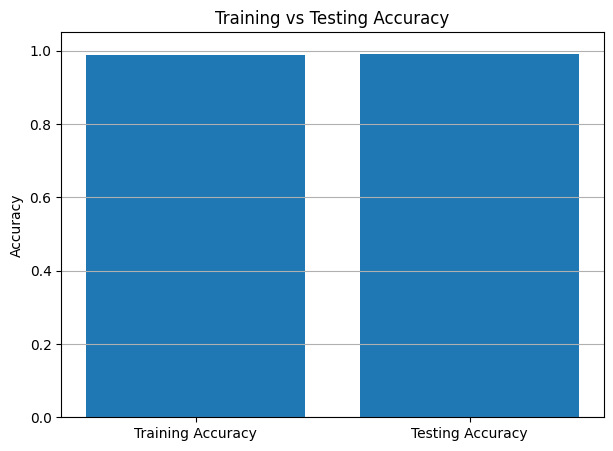

In [ ]:
train_acc = history.history['accuracy'][-1]
test_acc = test_accuracy

plt.figure(figsize=(7,5))

plt.bar(['Training Accuracy', 'Testing Accuracy'],
        [train_acc, test_acc])

plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis='y')
plt.show()

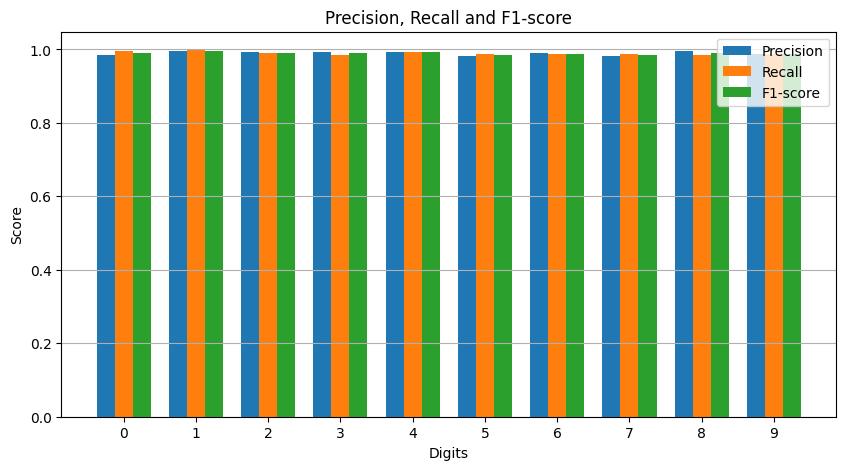

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred_classes, labels=range(10)
)

plt.figure(figsize=(10,5))

x = np.arange(10)
width = 0.25

plt.bar(x-width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x+width, f1, width, label='F1-score')

plt.xlabel("Digits")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-score")
plt.xticks(x, range(10))
plt.legend()
plt.grid(axis='y')
plt.show()

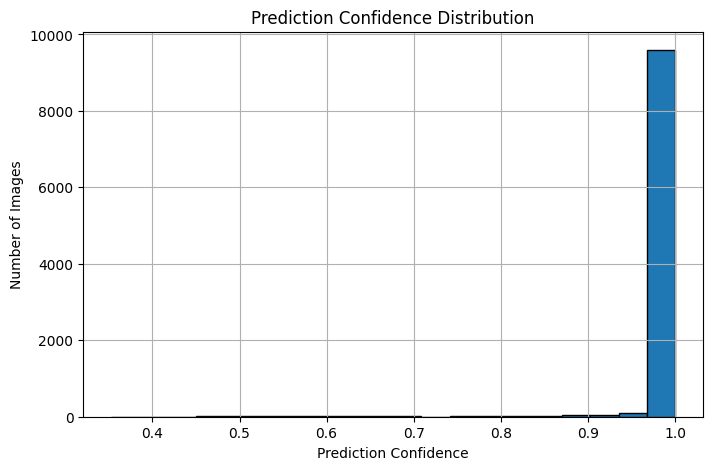

In [ ]:
confidence = np.max(y_pred, axis=1)

plt.figure(figsize=(8,5))

plt.hist(confidence, bins=20, edgecolor='black')

plt.title("Prediction Confidence Distribution")
plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Images")
plt.grid()
plt.show()

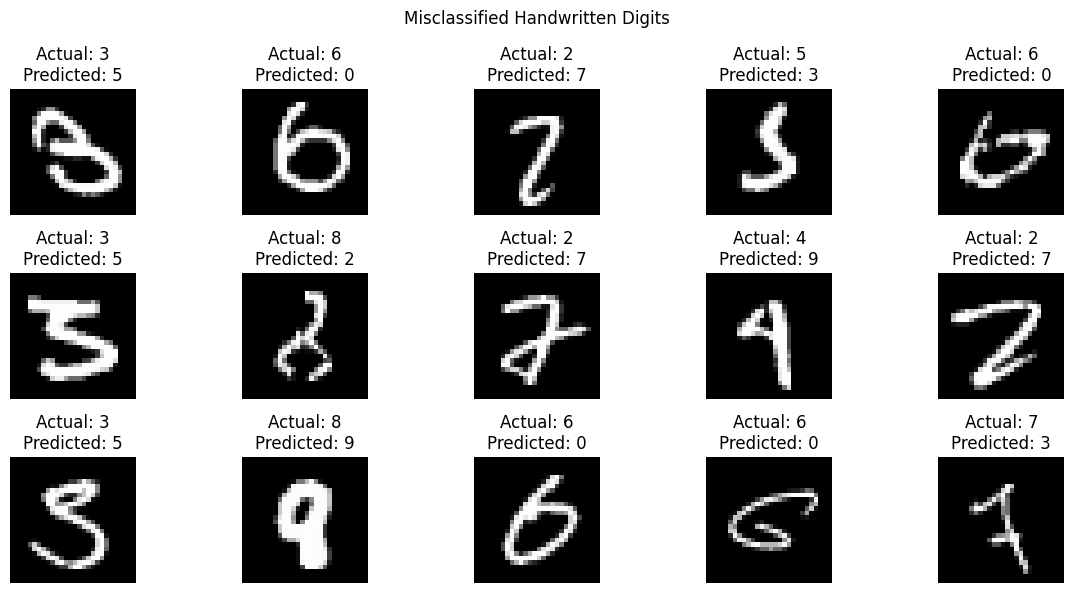

In [ ]:
wrong_indices = np.where(
    y_pred_classes != y_test
)[0]

plt.figure(figsize=(12,6))

for i in range(min(15, len(wrong_indices))):
    idx = wrong_indices[i]

    plt.subplot(3,5,i+1)

    plt.imshow(X_test[idx].squeeze(), cmap='gray')

    plt.title(
        "Actual: " + str(y_test[idx]) +
        "\nPredicted: " + str(y_pred_classes[idx])
    )

    plt.axis('off')

plt.suptitle("Misclassified Handwritten Digits")
plt.tight_layout()
plt.show()

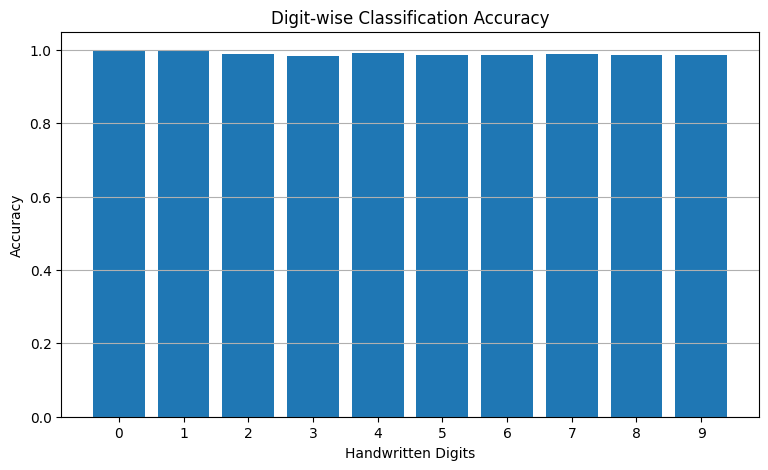

In [ ]:
digit_accuracy = []

for digit in range(10):
    mask = (y_test == digit)
    acc = np.mean(y_pred_classes[mask] == y_test[mask])
    digit_accuracy.append(acc)

plt.figure(figsize=(9,5))

plt.bar(range(10), digit_accuracy)

plt.title("Digit-wise Classification Accuracy")
plt.xlabel("Handwritten Digits")
plt.ylabel("Accuracy")
plt.xticks(range(10))
plt.ylim(0, 1.05)
plt.grid(axis='y')
plt.show()

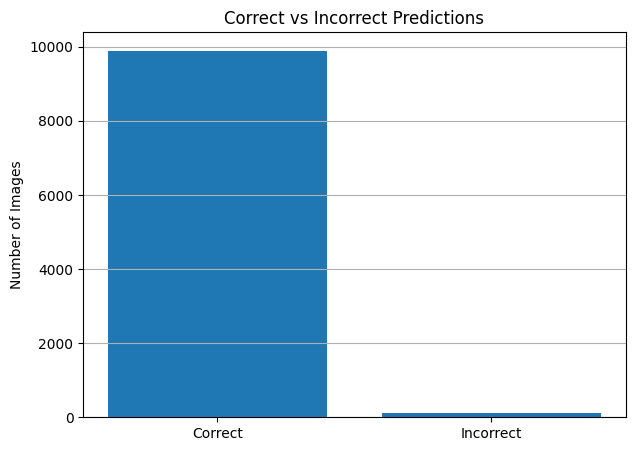

In [ ]:
correct = np.sum(y_pred_classes == y_test)
incorrect = np.sum(y_pred_classes != y_test)

plt.figure(figsize=(7,5))

plt.bar(['Correct', 'Incorrect'],
        [correct, incorrect])

plt.title("Correct vs Incorrect Predictions")
plt.ylabel("Number of Images")
plt.grid(axis='y')
plt.show()